# 03 — Améliorer le KNN

**Point de départ** (notebook 02, jeu dev) : le KNN naïf fait ~105 W quelle que soit la longueur du trou, même sur les trous d'un point où l'interpolation fait 62 W. Il copie la forme des voisines *à leur niveau à elles* et ignore les points observés juste autour du trou.

**Règles** : tous les réglages se font sur **dev** ; la configuration retenue est vérifiée sur **real** ; le **holdout** n'est pas touché. Chaque variante est ajoutée au registre `reports/results.csv`.

| Section | Contenu |
|---|---|
| a | Distance : MAE ou L2, brute ou forme seule, globale ou locale |
| b | Mise à l'échelle des voisines et ancrage aux bords des trous |
| c | Réglage fin de l'ancrage |
| d | Nombre de voisines K et agrégation |
| e | Choix final, comparaisons appariées |
| f | Le parcours, classe par classe, et vérification sur real |
| g | Taille du réservoir : courbe d'apprentissage et extrapolation |
| h | Un exemple |
| — | Constat → conséquence |

**L'ancrage en une phrase** : prédiction = KNN + résidu (observé − KNN) mesuré aux bords du trou et interpolé le long du trou. C'est équivalent à *interpolation de la courbe + (forme des voisines − interpolation de cette forme)* : on garde les niveaux aux bords, et la forme des voisines à l'intérieur.

In [1]:
# Imports et configuration
import itertools
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from enedis_imputation import SEED
from enedis_imputation.data import load_test, load_train
from enedis_imputation.holes import LENGTH_LABELS, hole_runs
from enedis_imputation.knn import (
    BEST_DISTANCE,
    BEST_PREDICTOR,
    Distance,
    Predictor,
    predict,
    search,
)
from enedis_imputation.methods import knn_median, linear_interpolation
from enedis_imputation.validation import Split, evaluate, load_split, paired_difference
from enedis_imputation.viz import PALETTE as P
from enedis_imputation.viz import method_color, plot_imputation, save_fig, set_conclusion, set_style

set_style()
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_colwidth", 80)

dev, real = load_split("dev"), load_split("real")  # le holdout n'est pas chargé
_cache: dict = {}


def neighbors(split: Split, distance: Distance, k_max: int = 50):
    """Recherche des voisines, faite une fois par (jeu, distance) puis réutilisée."""
    key = (split.name, split.reservoir.shape[1], distance)
    if key not in _cache:
        _cache[key] = search(split.X_holed, split.reservoir, distance, k_max=k_max)
    return _cache[key]


def run(split: Split, distance: Distance, predictor: Predictor, register: bool = True):
    """Évalue une variante ; le temps de recherche des voisines est compté dans son temps."""
    nb = neighbors(split, distance)
    return evaluate(
        lambda X, R: predict(X, R, nb, predictor),
        split,
        name=f"KNN | {distance.label} | {predictor.label}",
        setup_seconds=nb.seconds,
        register=register,
    )


def row(result) -> dict:
    """Ligne de tableau : MAE globale, IC, MAE par classe, temps."""
    return {
        "MAE": result.mae,
        "IC bas": result.ci[0],
        "IC haut": result.ci[1],
        **result.by_class["mae"].to_dict(),
        "secondes": result.seconds,
    }


# Références du notebook 02, réévaluées ici pour les comparaisons appariées
ref = {
    "interp": evaluate(linear_interpolation, dev, name="Interpolation linéaire"),
    "naive": evaluate(knn_median, dev, name="KNN naïf (médiane de 5)"),
}
pd.DataFrame({k: row(r) for k, r in ref.items()}).T

,MAE,IC bas,IC haut,1,2,3-6,7-48,>48,secondes
interp,104.29,98.52,109.87,62.20,71.88,77.43,143.36,154.06,0.11
naive,106.12,101.23,111.11,104.59,103.66,106.98,106.57,113.55,26.27


## a. Distance

Huit distances : **MAE (L1) ou L2**, sur les **courbes brutes** ou sur la **forme seule** (courbes centrées-réduites ; en L2, c'est exactement 1 − corrélation sur les points observés), sur **toute la courbe** ou sur une **fenêtre locale** (points observés à moins de 16 pas d'un trou). Chacune est jugée en version naïve (K = 5, médiane) et avec l'ancrage le plus simple (résidu pris sur le seul point voisin du trou).

Les distances L2 se calculent par produits matriciels masqués, ‖x − r‖²_w = Σw·x² − 2(w·x)·r + w·r², par blocs de cibles ; la L1 n'a pas d'identité équivalente et reste une boucle par courbe.

In [2]:
distances = [
    Distance(metric, shape, window)
    for metric, shape, window in itertools.product(["l2", "l1"], [False, True], [None, 16])
]
stage_a = {}
for d in distances:
    for anchor in (False, True):
        r = run(dev, d, Predictor(k=5, anchor=anchor))
        stage_a[(d.label, "ancré" if anchor else "naïf")] = row(r)
stage_a = pd.DataFrame(stage_a).T
stage_a.index.names = ["distance", "version"]
display(stage_a.round(1))
print("Temps de recherche des voisines (s) :")
print({d.label: round(neighbors(dev, d).seconds, 1) for d in distances})

MAE  IC bas  IC haut      1      2    3-6   7-48  \
distance        version                                                       
L2 brut global  naïf    111.30  106.30   116.30 110.60 109.50 110.80 111.10   
                ancré    98.20   93.20   103.00  65.40  75.00  79.30 127.60   
L2 brut ±16     naïf    111.10  105.90   116.10 110.00 108.70 111.40 111.20   
                ancré    98.40   93.40   103.40  65.40  75.10  79.70 127.70   
L2 forme global naïf    202.40  192.30   212.80 199.00 199.70 202.30 201.90   
                ancré   109.90  104.90   114.70  74.90  85.30  91.30 141.80   
L2 forme ±16    naïf    199.10  189.00   209.50 197.20 198.20 204.00 196.70   
                ancré   108.80  103.90   113.70  74.70  84.70  91.40 139.20   
L1 brut global  naïf    106.10  101.20   111.10 104.60 103.70 107.00 106.60   
                ancré    97.00   92.20   101.90  64.90  74.50  80.10 126.10   
L1 brut ±16     naïf    105.70  100.80   110.50 104.00 103.20 106.80 105.80   
                ancré    97.10   92.10   101.70  64.90  74.50  79.60 125.70   
L1 forme global naïf    220.30  208.30   232.60 217.20 215.10 224.10 216.50   
                ancré   101.30   96.20   106.30  67.10  77.00  83.70 131.80   
L1 forme ±16    naïf    223.70  211.70   236.50 220.60 218.10 228.50 219.50   
                ancré   101.10   96.20   106.00  67.10  77.00  83.50 130.80   

                           >48  secondes  
distance        version                   
L2 brut global  naïf    118.00      2.00  
                ancré   137.50      2.20  
L2 brut ±16     naïf    118.10      1.90  
                ancré   138.00      2.10  
L2 forme global naïf    221.20      2.40  
                ancré   148.70      2.60  
L2 forme ±16    naïf    215.80      2.30  
                ancré   149.80      2.50  
L1 brut global  naïf    113.50    106.40  
                ancré   133.20    106.70  
L1 brut ±16     naïf    115.40     82.50  
                ancré   135.10     82.80  
L1 forme global naïf    254.60     95.90  
                ancré   142.10     96.10  
L1 forme ±16    naïf    259.40     82.50  
                ancré   144.50     82.70

Temps de recherche des voisines (s) :
{'L2 brut global': 1.7, 'L2 brut ±16': 1.6, 'L2 forme global': 2.1, 'L2 forme ±16': 2.0, 'L1 brut global': 106.1, 'L1 brut ±16': 82.2, 'L1 forme global': 95.6, 'L1 forme ±16': 82.2}


**Constat → conséquence (distance)**

- **L'ancrage règle les trous courts et dégrade les trous longs.** Avec la distance L1 brute :
  - trous d'1 point : 105 → 65 W ;
  - trous de 7–48 points : 107 → 126 W.
  
  Le résidu mesuré sur un seul point au bord est bruité, et l'interpolation linéaire le propage sur toute la longueur du trou. → Il faudra **atténuer l'ancre au milieu des longs trous** (section c).
- **La forme seule, sans mise à l'échelle, est catastrophique** (200 W et plus) : les voisines ont la bonne forme, mais pas le bon niveau. → Elle n'a de sens qu'avec une mise à l'échelle (section b).
- **L1 contre L2** : la L1 gagne ~1 W en version ancrée (97,0 contre 98,2 W), mais coûte **45 fois plus de temps** (94 s contre 2 s), faute d'identité matricielle.
- **La fenêtre locale (±16 pas) ne change rien** (moins de 1 W).

## b. Mise à l'échelle des voisines et ancrage

Chaque voisine est ajustée sur les points observés de la cible : **aucune** mise à l'échelle, **multiplicative** (a·r), **affine** a·r + b par moindres carrés, ou **affine** avec la pente des moindres carrés et une ordonnée **médiane** (plus robuste aux pics). On croise avec quatre ancrages : point voisin seul (h = 1) ou moyenne des 2 points voisins (h = 2), sans atténuation ou avec atténuation (τ) au milieu des longs trous.

In [3]:
anchors = [(1, None), (2, None), (1, 3.0), (2, 6.0)]
stage_b = {}
for d in [Distance("l2"), Distance("l2", shape=True)]:
    for scaling in ["none", "mult", "affine_ls", "affine_med"]:
        for h, tau in anchors:
            p = Predictor(k=5, scaling=scaling, anchor=True, anchor_points=h, anchor_decay=tau)
            stage_b[(d.label, scaling, f"h={h}, τ={tau or '∞'}")] = row(run(dev, d, p))
stage_b = pd.DataFrame(stage_b).T
stage_b.index.names = ["distance", "mise à l'échelle", "ancrage"]
display(
    stage_b.reset_index()
    .pivot_table(index=["distance", "mise à l'échelle"], columns="ancrage", values="MAE")
    .round(1)
)
best_b = stage_b["MAE"].idxmin()
print("Meilleure combinaison :", best_b, f"→ {stage_b['MAE'].min():.2f} W")

ancrage                           h=1, τ=3.0  h=1, τ=∞  h=2, τ=6.0  h=2, τ=∞
distance        mise à l'échelle                                            
L2 brut global  affine_ls              87.80     97.60       90.10     98.10
                affine_med             86.40     97.60       88.90     98.10
                mult                   87.70     98.00       90.00     98.30
                none                   88.00     98.20       90.20     98.60
L2 forme global affine_ls              84.20     93.10       86.30     93.00
                affine_med             83.20     93.00       85.40     93.00
                mult                   89.30     96.40       90.60     96.00
                none                  128.60    109.90      125.10    109.40

Meilleure combinaison : ('L2 forme global', 'affine_med', 'h=1, τ=3.0') → 83.15 W


**Constat → conséquence (mise à l'échelle et ancrage)**

- **La mise à l'échelle rend la distance « forme » gagnante.** Avec l'ancrage h = 1, τ = 3 :
  - forme sans mise à l'échelle : 128,6 W ;
  - forme avec mise à l'échelle affine à ordonnée médiane : **83,2 W**.
  
  Sur les courbes brutes, l'apport de la mise à l'échelle est bien plus faible (88,0 → 86,4 W). L'idée est cohérente : on choisit les voisines **sur leur forme**, puis on les ramène **au niveau de la cible**.
- **L'ordonnée médiane bat de peu les moindres carrés** (83,2 contre 84,2 W) : elle résiste mieux aux pics de consommation.
- **L'atténuation de l'ancre est décisive.** Sans elle (τ = ∞), la meilleure combinaison est à ~93 W ; avec τ = 3 pas, elle descend à 83,2 W.

## c. Réglage fin de l'ancrage

In [4]:
d_best = Distance("l2", shape=True) if best_b[0].startswith("L2 forme") else Distance("l2")
scaling_best = best_b[1]
stage_c = {}
for h in [1, 2, 4]:
    for tau in [None, 2.0, 3.0, 6.0, 12.0]:
        p = Predictor(k=5, scaling=scaling_best, anchor=True, anchor_points=h, anchor_decay=tau)
        stage_c[(h, tau or np.inf)] = row(run(dev, d_best, p))
stage_c = pd.DataFrame(stage_c).T
stage_c.index.names = ["h (points d'ancre)", "τ (atténuation)"]
display(
    stage_c.reset_index()
    .pivot_table(index="h (points d'ancre)", columns="τ (atténuation)", values="MAE")
    .round(2)
)
h_best, tau_best = stage_c["MAE"].idxmin()
tau_best = None if np.isinf(tau_best) else tau_best
print(f"Meilleur ancrage : h = {h_best}, τ = {tau_best} → {stage_c['MAE'].min():.2f} W")
display(stage_c.loc[[(1, np.inf), (h_best, tau_best or np.inf)], LENGTH_LABELS].round(1))

τ (atténuation),2.00,3.00,6.00,12.00,inf
h (points d'ancre),,,,,
1,83.21,83.15,83.51,84.78,93.03
2,85.27,85.19,85.41,86.35,92.98
4,89.20,89.11,89.22,89.87,94.73


Meilleur ancrage : h = 1, τ = 3.0 → 83.15 W


1     2   3-6   7-48    >48
h (points d'ancre) τ (atténuation)                                
1                  inf             62.40 71.70 77.20 119.70 131.40
                   3.00            62.40 71.70 76.70  99.50 109.70

## d. Nombre de voisines K et agrégation

,median,wmean
1,87.96,87.96
3,84.11,83.23
5,83.15,82.45
10,82.34,82.11
20,82.63,82.41
50,83.39,83.23


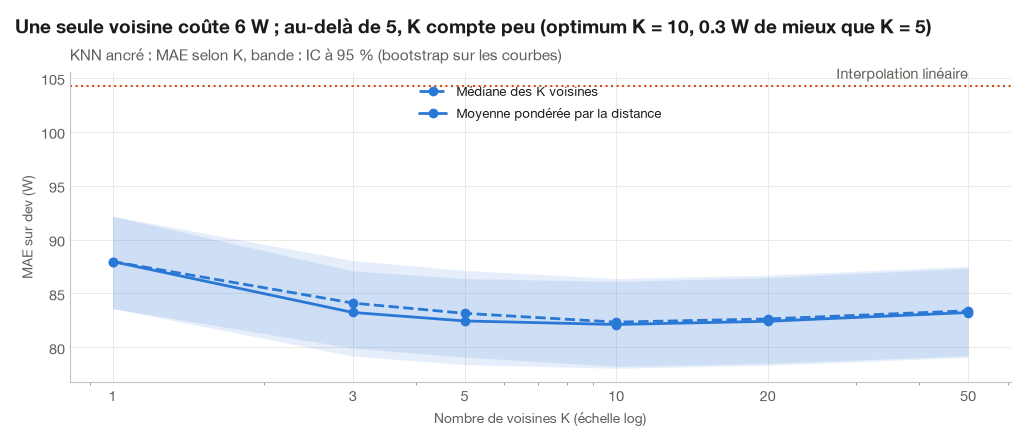

In [5]:
ks = [1, 3, 5, 10, 20, 50]
stage_d, results_d = {}, {}
for agg in ["median", "wmean"]:
    for k in ks:
        p = Predictor(
            k=k,
            aggregate=agg,
            scaling=scaling_best,
            anchor=True,
            anchor_points=h_best,
            anchor_decay=tau_best,
        )
        results_d[(agg, k)] = run(dev, d_best, p)
        stage_d[(agg, k)] = row(results_d[(agg, k)])
stage_d = pd.DataFrame(stage_d).T
display(pd.DataFrame({agg: stage_d.loc[agg, "MAE"] for agg in ["median", "wmean"]}).round(2))
agg_best, k_best = stage_d["MAE"].idxmin()

fig, ax = plt.subplots(figsize=(10, 4.2))
for agg, label, ls in [
    ("median", "Médiane des K voisines", "--"),
    ("wmean", "Moyenne pondérée par la distance", "-"),
]:
    t = stage_d.loc[agg]
    ax.fill_between(ks, t["IC bas"], t["IC haut"], color=P["knn"], alpha=0.12, lw=0)
    ax.plot(ks, t["MAE"], color=P["knn"], ls=ls, marker="o", ms=6, lw=2, label=label)
ax.axhline(ref["interp"].mae, color=method_color("interpolation"), ls=":", lw=1.5)
ax.annotate(
    "Interpolation linéaire",
    (ks[-1], ref["interp"].mae),
    xytext=(0, 5),
    textcoords="offset points",
    ha="right",
    color=P["ink_secondary"],
)
ax.set_xscale("log")
ax.set_xticks(ks, [str(k) for k in ks])
ax.set_xlabel("Nombre de voisines K (échelle log)")
ax.set_ylabel("MAE sur dev (W)")
ax.set_title("KNN ancré : MAE selon K, bande : IC à 95 % (bootstrap sur les courbes)")
ax.legend(loc="upper center")
gain_k = stage_d.loc[(agg_best, 5), "MAE"] - stage_d["MAE"].min()
loss_1 = stage_d.loc[(agg_best, 1), "MAE"] - stage_d["MAE"].min()
set_conclusion(
    fig,
    f"Une seule voisine coûte {loss_1:.0f} W ; au-delà de 5, K compte peu "
    f"(optimum K = {k_best}, {gain_k:.1f} W de mieux que K = 5)",
)
save_fig(fig, "k3_mae_selon_k");

## e. Choix final et comparaisons appariées

Les écarts entre les meilleures variantes sont petits devant l'IC global (±5 W). On les juge par **bootstrap apparié** : les deux méthodes sont évaluées sur les mêmes courbes, on rééchantillonne les courbes une fois pour les deux, et on regarde l'IC de la *différence*.

In [6]:
best_p = Predictor(
    k=k_best,
    aggregate=agg_best,
    scaling=scaling_best,
    anchor=True,
    anchor_points=h_best,
    anchor_decay=tau_best,
)
best = run(dev, d_best, best_p)
rivals = {
    "même config., médiane": (d_best, replace(best_p, aggregate="median")),
    "même config., K = 5": (d_best, replace(best_p, k=5)),
    "même config., fenêtre ±16": (Distance("l2", shape=True, window=16), best_p),
    "même config., distance L1 forme": (Distance("l1", shape=True), best_p),
    "même config., distance L2 brute": (Distance("l2"), best_p),
    "même config., non ancré": (d_best, replace(best_p, anchor=False)),
}
paired = {}
for name, (d, p) in rivals.items():
    r = run(dev, d, p)
    diff = paired_difference(r, best).loc["toutes"]
    paired[name] = {
        "MAE": r.mae,
        "écart au meilleur": diff["différence"],
        "IC bas": diff["IC bas"],
        "IC haut": diff["IC haut"],
        "secondes": r.seconds,
    }
paired = pd.DataFrame(paired).T
paired["significatif"] = paired["IC bas"] > 0
print(f"Configuration retenue : {d_best.label} | {best_p.label}")
print(
    f"MAE dev : {best.mae:.2f} W, IC95 [{best.ci[0]:.1f}, {best.ci[1]:.1f}], {best.seconds:.1f} s"
)
display(paired.round(2))
print(
    "Configuration identique à celle de knn.py (BEST_DISTANCE, BEST_PREDICTOR) :",
    d_best == BEST_DISTANCE and best_p == BEST_PREDICTOR,
)

Configuration retenue : L2 forme global | K=10 moy. pondérée, échelle affine_med, ancré h=1 τ=3
MAE dev : 82.11 W, IC95 [78.1, 86.1], 3.3 s


,MAE,écart au meilleur,IC bas,IC haut,secondes,significatif
"même config., médiane",82.34,0.22,0.09,0.35,3.70,True
"même config., K = 5",82.45,0.33,0.17,0.49,2.79,True
"même config., fenêtre ±16",82.19,0.07,-0.05,0.19,3.15,False
"même config., distance L1 forme",87.87,5.75,3.79,8.43,96.73,True
"même config., distance L2 brute",85.57,3.45,3.01,3.85,2.95,True
"même config., non ancré",102.48,20.37,19.01,21.77,2.95,True


Configuration identique à celle de knn.py (BEST_DISTANCE, BEST_PREDICTOR) : True


**Constat → conséquence (choix final)**

La configuration retenue est la suivante : distance **L2 sur la forme** (1 − corrélation sur les points observés, toute la courbe), **K = 10**, **moyenne pondérée** par la distance, **mise à l'échelle affine** (pente des moindres carrés, ordonnée médiane), **ancrage sur le point voisin du trou, atténué avec τ = 3 pas** (1 h 30). Elle donne **82,1 W sur dev**, et la recherche + prédiction prend environ 3 s pour 2 000 courbes.

Comparaisons appariées avec le meilleur :
- la médiane au lieu de la moyenne pondérée (+0,2 W) et K = 5 (+0,3 W) sont **significativement** moins bons, mais de peu ;
- la **fenêtre ±16** (+0,07 W, IC qui contient 0) ne fait **aucune différence** : on garde la version globale, plus simple ;
- la **distance L1 sur la forme** est nettement moins bonne (+5,8 W) **et** 30 fois plus lente ;
- la **distance L2 brute** coûte +3,5 W ;
- **sans ancrage**, +20,4 W : c'est l'idée qui pèse le plus.

## f. Le parcours, classe par classe, et vérification sur real

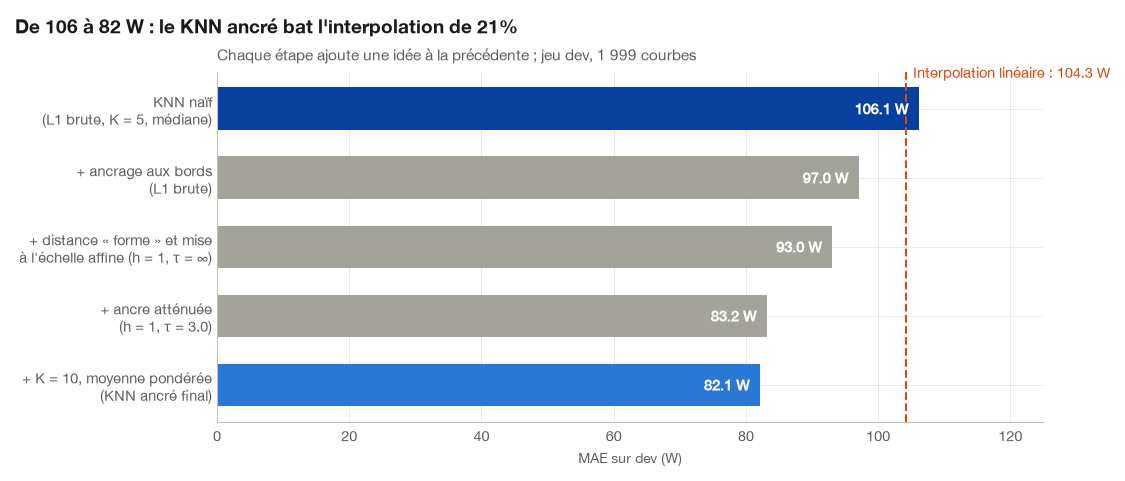

In [7]:
# Le parcours : chaque idée ajoutée une à une (valeurs déjà calculées ci-dessus)
agg_label = "moyenne pondérée" if agg_best == "wmean" else "médiane"
steps = [
    ("KNN naïf\n(L1 brute, K = 5, médiane)", ref["naive"].mae, P["knn_naive"]),
    (
        "+ ancrage aux bords\n(L1 brute)",
        stage_a.loc[("L1 brut global", "ancré"), "MAE"],
        P["neutral"],
    ),
    (
        "+ distance « forme » et mise\nà l'échelle affine (h = 1, τ = ∞)",
        stage_c.loc[(1, np.inf), "MAE"],
        P["neutral"],
    ),
    (
        f"+ ancre atténuée\n(h = {h_best}, τ = {tau_best or '∞'})",
        stage_c["MAE"].min(),
        P["neutral"],
    ),
    (f"+ K = {k_best}, {agg_label}\n(KNN ancré final)", best.mae, P["knn"]),
]
fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(steps))[::-1]
for yi, (_, v, color) in zip(y, steps, strict=True):
    ax.barh(yi, v, color=color, height=0.62)
    ax.text(v - 1.5, yi, f"{v:.1f} W", va="center", ha="right", color="white", fontweight="bold")
ax.axvline(ref["interp"].mae, color=method_color("interpolation"), ls="--", lw=1.5)
ax.text(
    ref["interp"].mae + 1,
    y[0] + 0.45,
    f"Interpolation linéaire : {ref['interp'].mae:.1f} W",
    color=method_color("interpolation"),
)
ax.set_yticks(y, [s[0] for s in steps])
ax.set_xlim(0, 125)
ax.set_xlabel("MAE sur dev (W)")
ax.set_title("Chaque étape ajoute une idée à la précédente ; jeu dev, 1 999 courbes")
gain = 1 - best.mae / ref["interp"].mae
set_conclusion(
    fig,
    f"De {ref['naive'].mae:.0f} à {best.mae:.0f} W : "
    f"le KNN ancré bat l'interpolation de {gain:.0%}",
)
save_fig(fig, "k1_parcours_knn");

In [8]:
# Vérification sur real (vrais trous) : la configuration choisie sur dev tient-elle ?
on_real = {
    "Interpolation linéaire": evaluate(linear_interpolation, real, name="Interpolation linéaire"),
    "KNN naïf (médiane de 5)": evaluate(knn_median, real, name="KNN naïf (médiane de 5)"),
    "KNN ancré": run(real, d_best, best_p),
}
on_dev = {
    "Interpolation linéaire": ref["interp"],
    "KNN naïf (médiane de 5)": ref["naive"],
    "KNN ancré": best,
}


def class_table(results: dict) -> pd.DataFrame:
    """MAE par classe (+ globale) de chaque méthode."""
    return pd.DataFrame(
        {k: [*r.by_class["mae"].to_numpy(), r.mae] for k, r in results.items()},
        index=[*LENGTH_LABELS, "toutes"],
    ).T


table = pd.concat({"dev": class_table(on_dev), "real": class_table(on_real)})
display(table.round(1))
print(
    f"KNN ancré, real : {on_real['KNN ancré'].mae:.2f} W, IC95 "
    f"[{on_real['KNN ancré'].ci[0]:.1f}, {on_real['KNN ancré'].ci[1]:.1f}]"
)
for split_name, res in [("dev", on_dev), ("real", on_real)]:
    d = paired_difference(res["KNN ancré"], res["Interpolation linéaire"]).loc["toutes"]
    print(
        f"{split_name} : KNN ancré − interpolation = {d['différence']:+.1f} W "
        f"[{d['IC bas']:+.1f}, {d['IC haut']:+.1f}]"
    )

1      2    3-6   7-48    >48  toutes
dev  Interpolation linéaire   62.20  71.90  77.40 143.40 154.10  104.30
     KNN naïf (médiane de 5) 104.60 103.70 107.00 106.60 113.50  106.10
     KNN ancré                60.90  70.10  75.30  99.10 108.90   82.10
real Interpolation linéaire   62.10  71.20  78.70 139.80 145.40  102.00
     KNN naïf (médiane de 5) 103.20 101.70 107.90 105.40  97.60  103.40
     KNN ancré                60.60  69.30  76.40  98.70  93.70   80.40

KNN ancré, real : 80.38 W, IC95 [75.1, 86.3]
dev : KNN ancré − interpolation = -22.2 W [-24.6, -19.5]


real : KNN ancré − interpolation = -21.6 W [-25.9, -18.0]


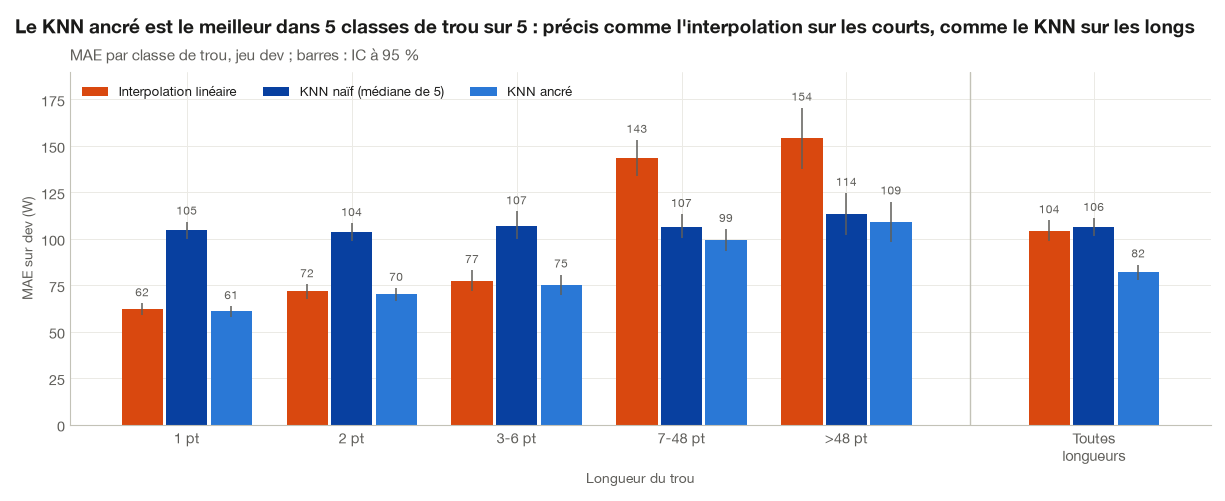

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.8))
groups = [*LENGTH_LABELS, "toutes"]
x = np.arange(len(groups)) + np.array([0, 0, 0, 0, 0, 0.5])
for i, (name, r) in enumerate(on_dev.items()):
    t = pd.concat(
        [
            r.by_class,
            pd.DataFrame({"mae": [r.mae], "low": [r.ci[0]], "high": [r.ci[1]]}, index=["toutes"]),
        ]
    ).loc[groups]
    xs = x + (i - 1) * 0.27
    ax.bar(xs, t["mae"], width=0.25, color=method_color(name), label=name)
    ax.errorbar(
        xs,
        t["mae"],
        yerr=[t["mae"] - t["low"], t["high"] - t["mae"]],
        fmt="none",
        ecolor=P["ink_secondary"],
        elinewidth=1.1,
    )
    for xi, v, hi in zip(xs, t["mae"], t["high"], strict=True):
        ax.text(
            xi,
            hi + 2.5,
            f"{v:.0f}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color=P["ink_secondary"],
        )
ax.axvline(x[-1] - 0.75, color=P["axis"], lw=1)
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS] + ["Toutes\nlongueurs"])
ax.set_xlabel("Longueur du trou")
ax.set_ylabel("MAE sur dev (W)")
ax.set_ylim(0, 190)
ax.set_title("MAE par classe de trou, jeu dev ; barres : IC à 95 %")
ax.legend(loc="upper left", ncol=3)
wins = (
    on_dev["KNN ancré"].by_class["mae"]
    <= np.minimum(
        on_dev["Interpolation linéaire"].by_class["mae"],
        on_dev["KNN naïf (médiane de 5)"].by_class["mae"],
    )
).sum()
set_conclusion(
    fig,
    f"Le KNN ancré est le meilleur dans {wins} classes de trou sur {len(LENGTH_LABELS)} : "
    "précis comme l'interpolation sur les courts, comme le KNN sur les longs",
)
save_fig(fig, "k2_mae_par_classe");

**Constat → conséquence (par classe, et sur real)**

| MAE (W) | 1 pt | 2 pts | 3–6 pts | 7–48 pts | > 48 pts | Toutes |
|---|---|---|---|---|---|---|
| **dev** — Interpolation | 62,2 | 71,9 | 77,4 | 143,4 | 154,1 | 104,3 |
| **dev** — KNN naïf | 104,6 | 103,7 | 107,0 | 106,6 | 113,5 | 106,1 |
| **dev** — KNN ancré | **60,9** | **70,1** | **75,3** | **99,1** | **108,9** | **82,1** |
| **real** — Interpolation | 62,1 | 71,2 | 78,7 | 139,8 | 145,4 | 102,0 |
| **real** — KNN naïf | 103,2 | 101,7 | 107,9 | 105,4 | 97,6 | 103,4 |
| **real** — KNN ancré | **60,6** | **69,3** | **76,4** | **98,7** | **93,7** | **80,4** |

- Le KNN ancré a la **plus faible erreur dans toutes les classes** :
  - sur les trous courts, il fait légèrement mieux que l'interpolation (ancrage) ;
  - sur les trous longs, il fait mieux que le KNN naïf (mise à l'échelle et ancre atténuée).
- **La configuration choisie sur dev tient sur les vrais trous** :
  - 80,4 W sur real, avec un IC à 95 % de [75,1 ; 86,3] ;
  - gain sur l'interpolation de −21,6 W [−25,9 ; −18,0] sur real, contre −22,2 W sur dev ;
  - il n'y a pas de sur-ajustement à dev.
- Il bat aussi la combinaison idéale « meilleure méthode naïve par classe » du notebook 02 (86,2 W) : **une seule méthode fait mieux que l'aiguillage entre deux méthodes naïves.**

## g. Taille du réservoir : courbe d'apprentissage

Plus le réservoir est grand, plus les voisines sont proches. On mesure la MAE sur dev avec des réservoirs emboîtés de 1 000 à 16 001 courbes, puis on extrapole à la taille du réservoir de la soumission : toutes les courbes complètes du train (y compris les cibles dev et holdout, qui redeviennent de simples voisines) et du test, aux mêmes dates.

In [10]:
X_full, _, _ = load_train()
T_full, _ = load_test()
n_final = int(X_full.notna().all().sum() + T_full.notna().all().sum())
print(f"Réservoir de la soumission : {n_final:,} courbes".replace(",", " "))

order = rng.permutation(dev.reservoir.columns.to_numpy())
sizes = [1000, 2000, 4000, 8000, len(order)]
curve = {}
for n in sizes:
    sub = Split("dev", dev.X_holed, dev.y, dev.reservoir[order[:n]])
    nb = search(sub.X_holed, sub.reservoir, d_best, k_max=best_p.k)
    r = evaluate(
        lambda X, R, nb=nb: predict(X, R, nb, best_p),
        sub,
        name=f"KNN ancré | réservoir {n}",
        setup_seconds=nb.seconds,
    )
    curve[n] = {"MAE": r.mae, "IC bas": r.ci[0], "IC haut": r.ci[1], "secondes": r.seconds}
curve = pd.DataFrame(curve).T
display(curve.round(2))

n_arr, mae_arr = curve.index.to_numpy(float), curve["MAE"].to_numpy()


# MAE en fonction de ln(n) : la pente sur tous les points (prudente) et sur les trois
# derniers (le gain par doublement augmente encore : pas de plancher visible). Une loi
# puissance avec plancher n'est pas identifiable sur ces données (ajustement sans plancher).
slope_all, icpt_all = np.polyfit(np.log(n_arr), mae_arr, 1)
slope_end, icpt_end = np.polyfit(np.log(n_arr[-3:]), mae_arr[-3:], 1)
fits = {
    "pente sur tous les points": (icpt_all, slope_all),
    "pente des 3 derniers points": (icpt_end, slope_end),
}
extrap = {k: icpt + slope * np.log(n_final) for k, (icpt, slope) in fits.items()}
for k, (_, slope) in fits.items():
    print(
        f"{k} : {slope * np.log(2):+.2f} W par doublement → {extrap[k]:.1f} W à {n_final} courbes"
    )

Réservoir de la soumission : 57 135 courbes


,MAE,IC bas,IC haut,secondes
1000,85.44,81.14,89.66,1.42
2000,84.72,80.44,88.92,1.44
4000,84.07,79.84,88.24,1.82
8000,83.08,78.93,87.22,2.12
16001,82.11,78.06,86.11,3.19


pente sur tous les points : -0.83 W par doublement → 80.7 W à 57135 courbes
pente des 3 derniers points : -0.98 W par doublement → 80.3 W à 57135 courbes


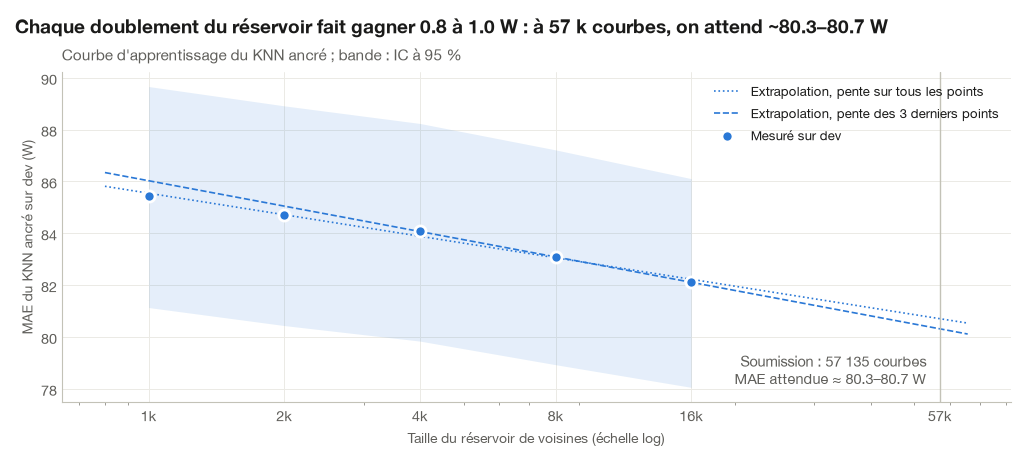

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.4))
grid = np.logspace(np.log10(800), np.log10(n_final * 1.15), 200)
ax.fill_between(n_arr, curve["IC bas"], curve["IC haut"], color=P["knn"], alpha=0.12, lw=0)
for (k, (icpt, slope)), ls in zip(fits.items(), [":", "--"], strict=True):
    ax.plot(
        grid,
        icpt + slope * np.log(grid),
        color=P["knn"],
        lw=1.2,
        ls=ls,
        label=f"Extrapolation, {k}",
    )
ax.plot(n_arr, mae_arr, "o", color=P["knn"], ms=8, mec="white", mew=2, label="Mesuré sur dev")
ax.axvline(n_final, color=P["axis"], lw=1)
lo, hi = sorted(extrap.values())
ax.annotate(
    f"Soumission : {n_final:,} courbes\nMAE attendue ≈ {lo:.1f}–{hi:.1f} W".replace(",", " "),
    (n_final, curve["IC bas"].min()),
    xytext=(-10, 0),
    textcoords="offset points",
    ha="right",
    va="bottom",
    color=P["ink_secondary"],
)
ax.set_xscale("log")
ax.set_xticks([1000, 2000, 4000, 8000, 16000, 57000], ["1k", "2k", "4k", "8k", "16k", "57k"])
ax.set_xlabel("Taille du réservoir de voisines (échelle log)")
ax.set_ylabel("MAE du KNN ancré sur dev (W)")
ax.set_title("Courbe d'apprentissage du KNN ancré ; bande : IC à 95 %")
ax.legend(loc="upper right")
set_conclusion(
    fig,
    f"Chaque doublement du réservoir fait gagner {-slope_all * np.log(2):.1f} à "
    f"{-slope_end * np.log(2):.1f} W : à {n_final / 1000:.0f} k courbes, on attend "
    f"~{lo:.1f}–{hi:.1f} W",
)
save_fig(fig, "k4_taille_reservoir");

## h. Un exemple : un long trou rempli par les trois méthodes

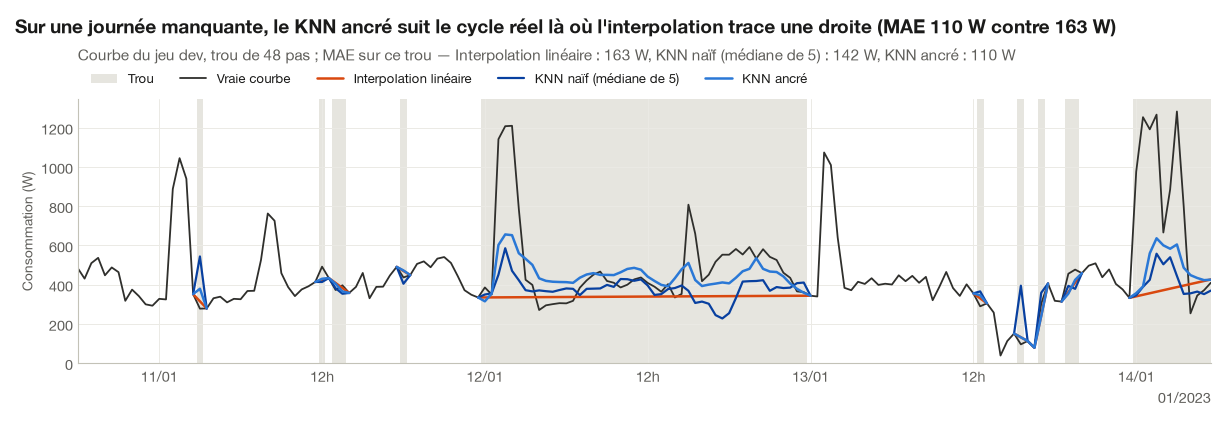

In [12]:
preds = {
    "Interpolation linéaire": linear_interpolation(dev.X_holed, dev.reservoir),
    "KNN naïf (médiane de 5)": knn_median(dev.X_holed, dev.reservoir),
    "KNN ancré": predict(dev.X_holed, dev.reservoir, neighbors(dev, d_best), best_p),
}
runs = hole_runs(dev.mask)
long = runs[runs["length"] == 48].copy()
y_arr = dev.y.to_numpy()
for name, pr in preds.items():
    arr = pr.to_numpy()
    long[name] = [
        np.abs(arr[s : s + n, c] - y_arr[s : s + n, c]).mean()
        for c, s, n in zip(long["curve"], long["start"], long["length"], strict=True)
    ]
# Exemple représentatif : gain du KNN ancré sur l'interpolation proche du gain médian,
# sur une courbe de niveau moyen à élevé (lisible)
long["gain"] = long["Interpolation linéaire"] - long["KNN ancré"]
level = dev.y.mean().to_numpy()[long["curve"]]
pool = long[(level > np.median(level)) & (long["gain"] > 0)]
ex = pool.loc[(pool["gain"] - pool["gain"].median()).abs().idxmin()]
c, s, n = int(ex["curve"]), int(ex["start"]), int(ex["length"])
col = dev.X_holed.columns[c]
fig = plot_imputation(
    dev.y[col],
    {k: v[col] for k, v in preds.items()},
    dev.mask[:, c],
    f"Sur une journée manquante, le KNN ancré suit le cycle réel là où l'interpolation trace "
    f"une droite (MAE {ex['KNN ancré']:.0f} W contre {ex['Interpolation linéaire']:.0f} W)",
    window=slice(max(0, s - 60), min(len(dev.y), s + n + 60)),
)
fig.axes[0].set_title(
    "Courbe du jeu dev, trou de 48 pas ; MAE sur ce trou — "
    + ", ".join(f"{k} : {ex[k]:.0f} W" for k in preds),
    pad=28,
)
save_fig(fig, "k5_exemple_long_trou");

## Constat → conséquence pour la modélisation

**Constat**
- **De 106 à 82 W sur dev (−21 % par rapport au benchmark), et 80,4 W sur real.** Trois idées font l'essentiel du gain :
  - **ancrer** la prédiction sur les points observés au bord des trous ;
  - **choisir les voisines sur leur forme**, puis les **remettre au niveau** de la cible (affine, ordonnée médiane) ;
  - **atténuer l'ancre** loin des bords, pour qu'au milieu d'un long trou on fasse confiance aux voisines.
- **Le choix de K et de l'agrégation pèse peu** (moins de 1 W entre 5 et 50) ; la fenêtre locale et la distance L1 n'apportent rien. La version L2 matricielle est à la fois la meilleure et la plus rapide : ~3 s pour 2 000 courbes et 16 000 voisines.
- **Plus de voisines, c'est mieux, et le gain ne s'essouffle pas encore** : de 0,7 à 1,0 W par doublement du réservoir. L'extrapolation au réservoir de la soumission (57 135 courbes, train + test complets) donne **~80,3–80,7 W sur dev**, soit 1,5 à 2 W de mieux qu'avec 16 000 courbes. C'est une extrapolation au-delà des mesures, à prendre comme un ordre de grandeur.

**→ Conséquence**
- `knn.anchored_knn` (constantes `BEST_DISTANCE`, `BEST_PREDICTOR`) devient la **méthode de référence** à battre. Pour la soumission, son réservoir sera **toutes les courbes complètes du train et du test**.
- **Ce qui reste à gagner est dans les trous longs** : 99 W sur 7–48 points et 109 W au-delà, contre 61 W sur les trous d'un point. Prochaine étape : un **LightGBM** qui apprend à corriger ou à combiner les prédictions selon le contexte (longueur du trou, position dans le trou, heure, niveau de la courbe, accord entre voisines, interpolation, KNN ancré). Il sera entraîné sur des faux trous greffés hors de dev, pour garder dev propre.
- La dispersion des voisines dans le trou est une mesure naturelle de l'incertitude, qui servira aux **intervalles de confiance**.